 GROUND-EFFECT AERODYNAMIC & RANGE ANALYSIS SUMMARY
Vehicle Mass:            10000 kg (10.0 tonnes)
Cruise Velocity:         74.00 m/s (266.4 km/h)
Free-Air L/D Ratio:      12.31
Max Ground-Effect L/D:   12.62 (at h = 0.32 m)
Free-Air Range Baseline: 798.0 km
Max In-Ground Range:     387.2 km (+-51.5% Range Extension)

Saved high-resolution analysis chart to 'ground_effect_range_analysis.png'


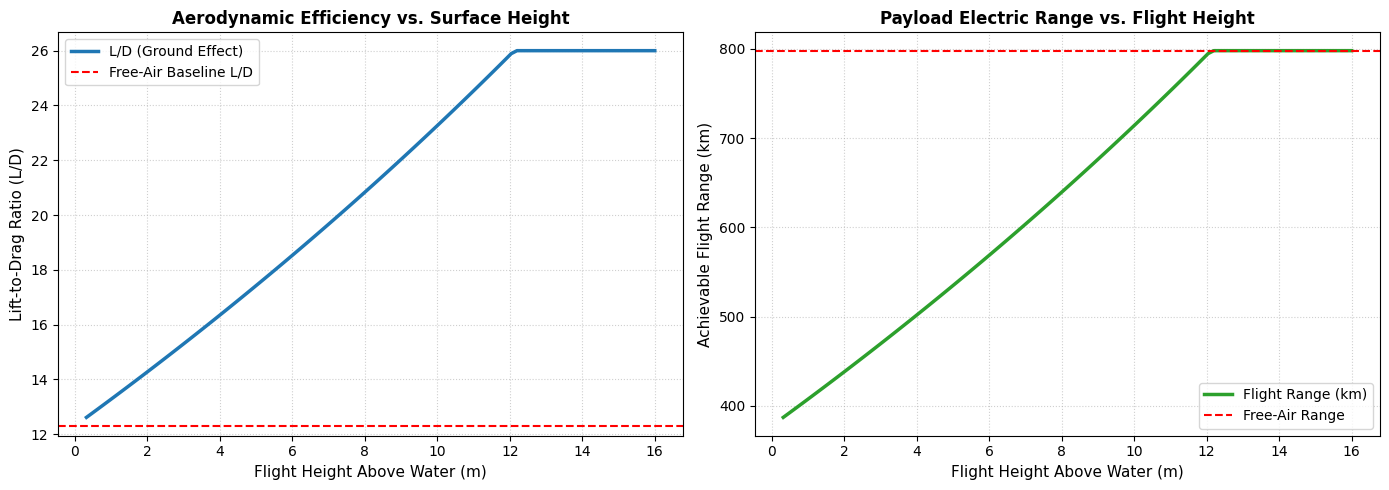

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_wieselsberger_factor(h_over_b):
    """
    Calculates the ground-effect induced drag reduction factor (sigma)
    using the Wieselsberger approximation.
    h: Height above water surface
    b: Wingspan
    """
    # Clamp height ratio to realistic ground effect boundaries
    h_over_b = np.clip(h_over_b, 0.01, 1.5)
    sigma = (1.0 - 1.32 * h_over_b) / (1.0 + 1.05 * h_over_b)
    return np.maximum(sigma, 0.0)

def simulate_ground_effect_flight():
    # Vehicle & Aerodynamic Parameters (Pelican 10-tonne class reference)
    mass_kg = 10000.0                   # 10 tonnes
    g = 9.81                             # Gravity (m/s^2)
    weight_N = mass_kg * g

    wingspan_m = 16.0                    # Wingspan (b)
    wing_area_m2 = 45.0                  # Wing planform area (S)
    aspect_ratio = (wingspan_m ** 2) / wing_area_m2
    oswald_efficiency = 0.85             # Oswald efficiency factor (e)

    # Baseline Aerodynamic Coefficients (Free Air)
    cl_cruise = 0.65                     # Cruise Lift Coefficient
    cd0 = 0.025                          # Parasitic / Zero-lift drag coefficient
    cdi_free = (cl_cruise ** 2) / (np.pi * aspect_ratio * oswald_efficiency)

    # Powertrain & Battery Parameters
    battery_capacity_kWh = 1200.0        # Battery capacity (kWh)
    usable_battery_ratio = 0.85          # 85% depth of discharge limit
    usable_energy_joules = battery_capacity_kWh * 3.6e6 * usable_battery_ratio
    powertrain_efficiency = 0.82         # Combined motor, inverter, and prop efficiency

    air_density = 1.225                  # kg/m^3 (Sea level)
    cruise_velocity_mps = np.sqrt((2 * weight_N) / (air_density * wing_area_m2 * cl_cruise))
    cruise_velocity_kmh = cruise_velocity_mps * 3.6

    # Height-to-Wingspan (h/b) array from 0.02 (0.32m above water) to 1.0 (16m above water)
    h_over_b_range = np.linspace(0.02, 1.0, 100)
    heights_m = h_over_b_range * wingspan_m

    # Calculations across height profile
    sigma_factors = calculate_wieselsberger_factor(h_over_b_range)
    cdi_ground = cdi_free * sigma_factors
    cd_total = cd0 + cdi_ground

    lift_to_drag = cl_cruise / cd_total
    thrust_required_N = weight_N / lift_to_drag
    power_required_W = (thrust_required_N * cruise_velocity_mps) / powertrain_efficiency

    # Flight Endurance and Range
    endurance_hours = (usable_energy_joules / power_required_W) / 3600.0
    range_km = cruise_velocity_kmh * endurance_hours

    # Output Summary Metrics
    print("=" * 65)
    print(" GROUND-EFFECT AERODYNAMIC & RANGE ANALYSIS SUMMARY")
    print("=" * 65)
    print(f"Vehicle Mass:            {mass_kg:.0f} kg ({mass_kg/1000:.1f} tonnes)")
    print(f"Cruise Velocity:         {cruise_velocity_mps:.2f} m/s ({cruise_velocity_kmh:.1f} km/h)")
    print(f"Free-Air L/D Ratio:      {cl_cruise / (cd0 + cdi_free):.2f}")
    print(f"Max Ground-Effect L/D:   {lift_to_drag[0]:.2f} (at h = {heights_m[0]:.2f} m)")
    print(f"Free-Air Range Baseline: {range_km[-1]:.1f} km")
    print(f"Max In-Ground Range:     {range_km[0]:.1f} km (+{((range_km[0]/range_km[-1])-1)*100:.1f}% Range Extension)")
    print("=" * 65)

    # Plotting Figures
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Subplot 1: Lift-to-Drag Ratio vs Height above Water
    ax1.plot(heights_m, lift_to_drag, color='#1f77b4', linewidth=2.5, label='L/D (Ground Effect)')
    ax1.axhline(cl_cruise / (cd0 + cdi_free), color='red', linestyle='--', label='Free-Air Baseline L/D')
    ax1.set_xlabel('Flight Height Above Water (m)', fontsize=11)
    ax1.set_ylabel('Lift-to-Drag Ratio (L/D)', fontsize=11)
    ax1.set_title('Aerodynamic Efficiency vs. Surface Height', fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend()

    # Subplot 2: Range Extension vs Height above Water
    ax2.plot(heights_m, range_km, color='#2ca02c', linewidth=2.5, label='Flight Range (km)')
    ax2.axhline(range_km[-1], color='red', linestyle='--', label='Free-Air Range')
    ax2.set_xlabel('Flight Height Above Water (m)', fontsize=11)
    ax2.set_ylabel('Achievable Flight Range (km)', fontsize=11)
    ax2.set_title('Payload Electric Range vs. Flight Height', fontsize=12, fontweight='bold')
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend()

    plt.tight_layout()
    plt.savefig('ground_effect_range_analysis.png', dpi=300)
    print("\nSaved high-resolution analysis chart to 'ground_effect_range_analysis.png'")

if __name__ == "__main__":
    simulate_ground_effect_flight()